In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/biohub-cell-tracking-during-development/sample_submission.csv
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/zarr.json
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/zarr.json
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/7/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/47/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/17/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/81/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/19/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/22/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845

In [2]:
pip install geff


Note: you may need to restart the kernel to use updated packages.


In [ ]:
from geff import read
graph, metadata = read("/kaggle/input/competitions/biohub-cell-tracking-during-development/train/44b6_0113de3b.geff", backend="networkx")

In [ ]:
print(graph)

In [ ]:
for node_id, attrs in list(graph.nodes(data=True))[:5]:
    print(node_id, attrs)

In [ ]:
division_nodes = [n for n, d in graph.out_degree() if d == 2]
print(f"{len(division_nodes)} division nodes out of {graph.number_of_nodes()} total")

In [ ]:
if division_nodes:
    parent = division_nodes[0]
    children = list(graph.successors(parent))
    print("parent:", parent, graph.nodes[parent])
    for c in children:
        print("child:", c, graph.nodes[c])

In [ ]:
import glob
from geff import read

for path in sorted(glob.glob("/kaggle/input/competitions/biohub-cell-tracking-during-development/train/*.geff")):
    g, meta = read(path, backend="networkx")
    print(path, g.number_of_nodes(), g.number_of_edges(), meta.extra.get("estimated_number_of_nodes"))

In [5]:
pip install zarr

Note: you may need to restart the kernel to use updated packages.


In [7]:
import zarr
z = zarr.open("/kaggle/input/competitions/biohub-cell-tracking-during-development/train/44b6_0113de3b.zarr", mode="r")
print(z)

<Group file:///kaggle/input/competitions/biohub-cell-tracking-during-development/train/44b6_0113de3b.zarr>


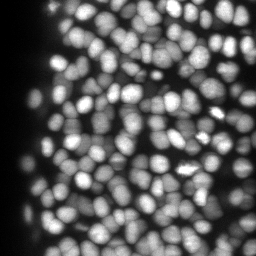

In [9]:
import numpy as np
import imageio
from IPython.display import Image

arr = z['0']
T = arr.shape[0]

frames = []
for t in range(T):
    vol = np.asarray(arr[t])
    proj = vol.max(axis=0)      

    lo, hi = np.percentile(proj, [1, 99])
    proj = np.clip((proj.astype(np.float32) - lo) / (hi - lo + 1e-8), 0, 1)
    frame = (proj * 255).astype(np.uint8)
    frames.append(frame)

imageio.mimsave("/kaggle/working/embryo.gif", frames, duration=100, loop=0)
Image(filename="/kaggle/working/embryo.gif")

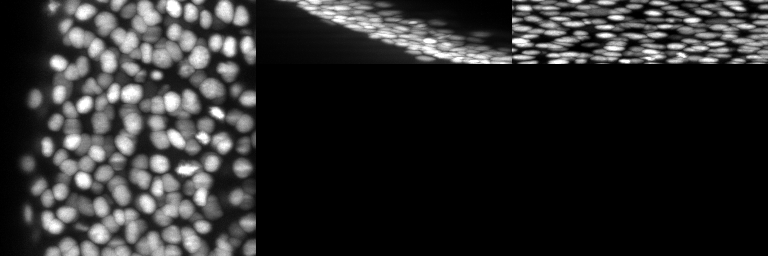

In [10]:
import numpy as np
import imageio

arr = z['0']  
T = arr.shape[0]

def normalize(img):
    lo, hi = np.percentile(img, [1, 99])
    img = np.clip((img.astype(np.float32) - lo) / (hi - lo + 1e-8), 0, 1)
    return (img * 255).astype(np.uint8)

frames = []
for t in range(T):
    vol = np.asarray(arr[t])              

    xy = normalize(vol.max(axis=0))       
    xz = normalize(vol.max(axis=1))      
    yz = normalize(vol.max(axis=2))       

    pad_h = xy.shape[0] - xz.shape[0]
    if pad_h > 0:
        xz = np.pad(xz, ((0, pad_h), (0, 0)))
        yz = np.pad(yz, ((0, pad_h), (0, 0)))

    tile = np.concatenate([xy, xz, yz], axis=1) 
    frames.append(tile)

imageio.mimsave("/kaggle/working/embryo_3views.gif", frames, fps=10, loop=0)
from IPython.display import Image
Image(filename="/kaggle/working/embryo_3views.gif")

In [ ]:
!pip uninstall -y kaleido
!pip install kaleido==0.2.1 -q

rendered t=0
rendered t=5
rendered t=10
rendered t=15
rendered t=20
rendered t=25
rendered t=30
rendered t=35
rendered t=40
rendered t=45
rendered t=50
rendered t=55
rendered t=60
rendered t=65
rendered t=70
rendered t=75
rendered t=80
rendered t=85
rendered t=90
rendered t=95


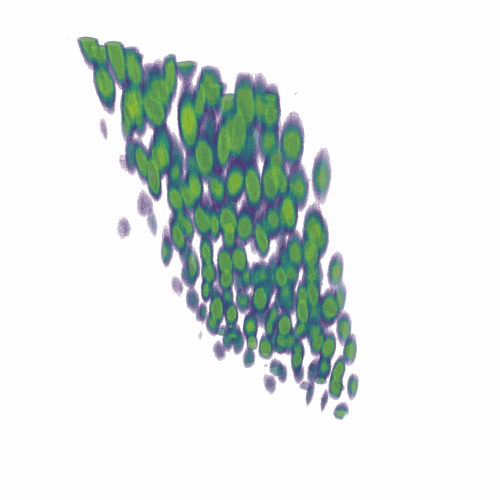

In [8]:
import numpy as np
import plotly.graph_objects as go
import imageio
import io
from PIL import Image as PILImage

arr = z['0']  # (100, 64, 256, 256) = (T, Z, Y, X)
T = arr.shape[0]

# --- speed knobs -----------------------------------------------------
FRAME_STEP = 5          # take every 5th timepoint (20 frames instead of 100)
DOWNSAMPLE = 2          # halve Y/X resolution for speed
Z_SCALE = 1.625 / 0.40625   # anisotropy ratio, so z isn't visually squashed
# ----------------------------------------------------------------------

timepoints = range(0, T, FRAME_STEP)
frames_png = []

for t in timepoints:
    vol = np.asarray(arr[t])[:, ::DOWNSAMPLE, ::DOWNSAMPLE].astype(np.float32)
    Z, Y, X = vol.shape

    lo, hi = np.percentile(vol, [90, 99.5])  # keep only brighter voxels (cells), drop background
    vol_norm = np.clip((vol - lo) / (hi - lo + 1e-8), 0, 1)

    zg, yg, xg = np.mgrid[0:Z, 0:Y, 0:X]

    fig = go.Figure(data=go.Volume(
        x=xg.flatten(), y=yg.flatten(), z=(zg * Z_SCALE).flatten(),
        value=vol_norm.flatten(),
        isomin=0.15, isomax=1.0,
        opacity=0.1,
        surface_count=15,
        colorscale="Viridis",
        showscale=False,
    ))
    fig.update_layout(
        scene=dict(
            xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False),
            aspectmode="data",
        ),
        margin=dict(l=0, r=0, t=0, b=0),
        width=500, height=500,
    )

    png_bytes = fig.to_image(format="png", engine="kaleido")
    frames_png.append(np.array(PILImage.open(io.BytesIO(png_bytes))))
    print(f"rendered t={t}")

imageio.mimsave("/kaggle/working/embryo_3d.gif", frames_png, fps=4, loop=0)
from IPython.display import Image
Image(filename="/kaggle/working/embryo_3d.gif")